# Student Mental Health Risk Prediction
## Step 1: Exploratory Data Analysis (EDA)

### Objective
The purpose of this notebook is to understand the structure, quality, and relationships in our dataset before building any Machine Learning model.

As a best practice in AI engineering, we do not jump straight to training algorithms. Instead, we:
1. Inspect data types, shapes, and summary statistics.
2. Check for missing values and duplicates.
3. Understand the distribution of the target variable (`Mental_Health_Risk`).
4. Analyze numerical and categorical features.
5. Explore how different features relate to mental health risk.
6. Identify data quality issues to address in the preprocessing phase.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent

from src.data.load_data import load_raw_data

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print("Environment configured successfully!")


Environment configured successfully!


### 1. Load the Dataset
We use our reusable function `load_raw_data()` from `src.data.load_data`. This avoids hardcoding paths and ensures consistency across notebooks and production scripts.

In [2]:
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "student_mental_health.csv"

df = load_raw_data(RAW_DATA_PATH)
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 2000 rows, 17 columns


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


### 2. Dataset Overview & Data Types
Let's check the data types and memory usage. Notice if any columns need type conversion.


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   object 
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   object 
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   object 
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 19

### 3. Data Quality Checks: Missing Values & Duplicates
Missing data and duplicate records can distort machine learning models if not handled properly.

In [4]:
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")

# Check missing values
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_pct.round(2)
})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("Columns with missing values:")
display(missing_df)


Number of duplicate rows: 0
Columns with missing values:


,Missing Count,Percentage (%)
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


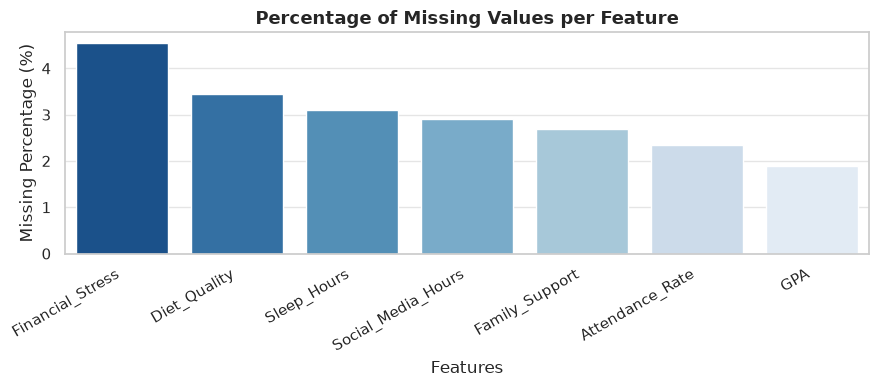

In [5]:
if not missing_df.empty:
    plt.figure(figsize=(9, 4))
    sns.barplot(x=missing_df.index, y=missing_df['Percentage (%)'], hue=missing_df.index, palette='Blues_r', legend=False)
    plt.title('Percentage of Missing Values per Feature', fontsize=13, weight='bold')
    plt.xlabel('Features')
    plt.ylabel('Missing Percentage (%)')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

**Observation on Missing Values:**
- 7 columns have missing values ranging from **1.9% to 4.5%**.
- None of the columns have a severe missing rate (>30%), so we do not need to drop any columns.
- Instead, in the preprocessing step, we will use **imputation**:
  - Median imputation for numerical features (robust to outliers).
  - Mode imputation (most frequent) for categorical features.

### 4. Unique Identifiers Check
Let's verify `Student_ID`. Identifiers have no generalizable predictive value and would cause data leakage or overfitting if left in the model.

In [8]:
unique_ids = df['Student_ID'].nunique()
print(f"Total rows: {len(df)} | Unique Student IDs: {unique_ids}")

Total rows: 2000 | Unique Student IDs: 2000


### 5. Target Variable Analysis (`Mental_Health_Risk`)
Understanding the class distribution is essential. A heavily imbalanced target requires techniques like class weighting or resampling.

Target Variable Distribution:


,Count,Percentage (%)
Mental_Health_Risk,,
High,680,34.0
Medium,660,33.0
Low,660,33.0


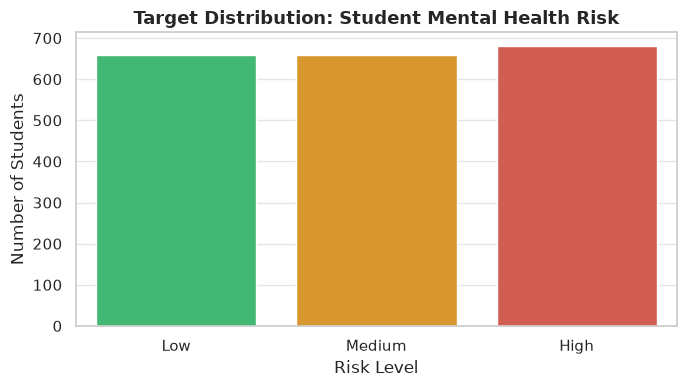

In [9]:
target_counts = df['Mental_Health_Risk'].value_counts()
target_pct = df['Mental_Health_Risk'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_pct.round(2)
})
print("Target Variable Distribution:")
display(target_summary)

plt.figure(figsize=(7, 4))
colors = {'Low': '#2ecc71', 'Medium': '#f39c12', 'High': '#e74c3c'}
sns.countplot(data=df, x='Mental_Health_Risk', order=['Low', 'Medium', 'High'], hue='Mental_Health_Risk', palette=colors, legend=False)
plt.title('Target Distribution: Student Mental Health Risk', fontsize=13, weight='bold')
plt.xlabel('Risk Level')
plt.ylabel('Number of Students')

# Ensure reports/figures exists and save figure
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "target_distribution.png", dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

**Observation on Target Variable:**
- The classes are balanced: ~33% Low, ~33% Medium, ~34% High.
- Because class balance is even, accuracy is a valid baseline metric, but we will still track **Precision, Recall, and F1-score** (macro and weighted) to ensure fairness across all risk tiers.

### 6. Numerical Features Analysis
Let's inspect the descriptive statistics: mean, standard deviation, min, median, and max.

In [10]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numerical columns ({len(num_cols)}):", num_cols)
df[num_cols].describe().round(2).T

Numerical columns (10): ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.13,2.14,17.0,20.00,21.00,23.00,29.00
Year_of_Study,2000.0,2.63,1.32,1.0,1.00,2.00,4.00,5.00
Sleep_Hours,1938.0,6.76,1.13,3.3,6.00,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,20.00,5.72,2.4,16.00,19.80,24.00,38.30
GPA,1962.0,2.56,0.34,1.5,2.32,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.01,1.15,2.1,5.22,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.55,1.66,3.3,7.40,8.50,9.70,14.00
Financial_Stress,1909.0,5.96,1.89,1.4,4.50,6.10,7.40,10.00
Family_Support,1946.0,6.52,1.84,1.7,5.10,6.70,8.00,9.90
Attendance_Rate,1953.0,85.08,7.22,54.4,80.30,85.10,90.00,100.00


Let's plot histograms with KDE to understand the distribution shape (normal, uniform, or skewed) of key numerical features.

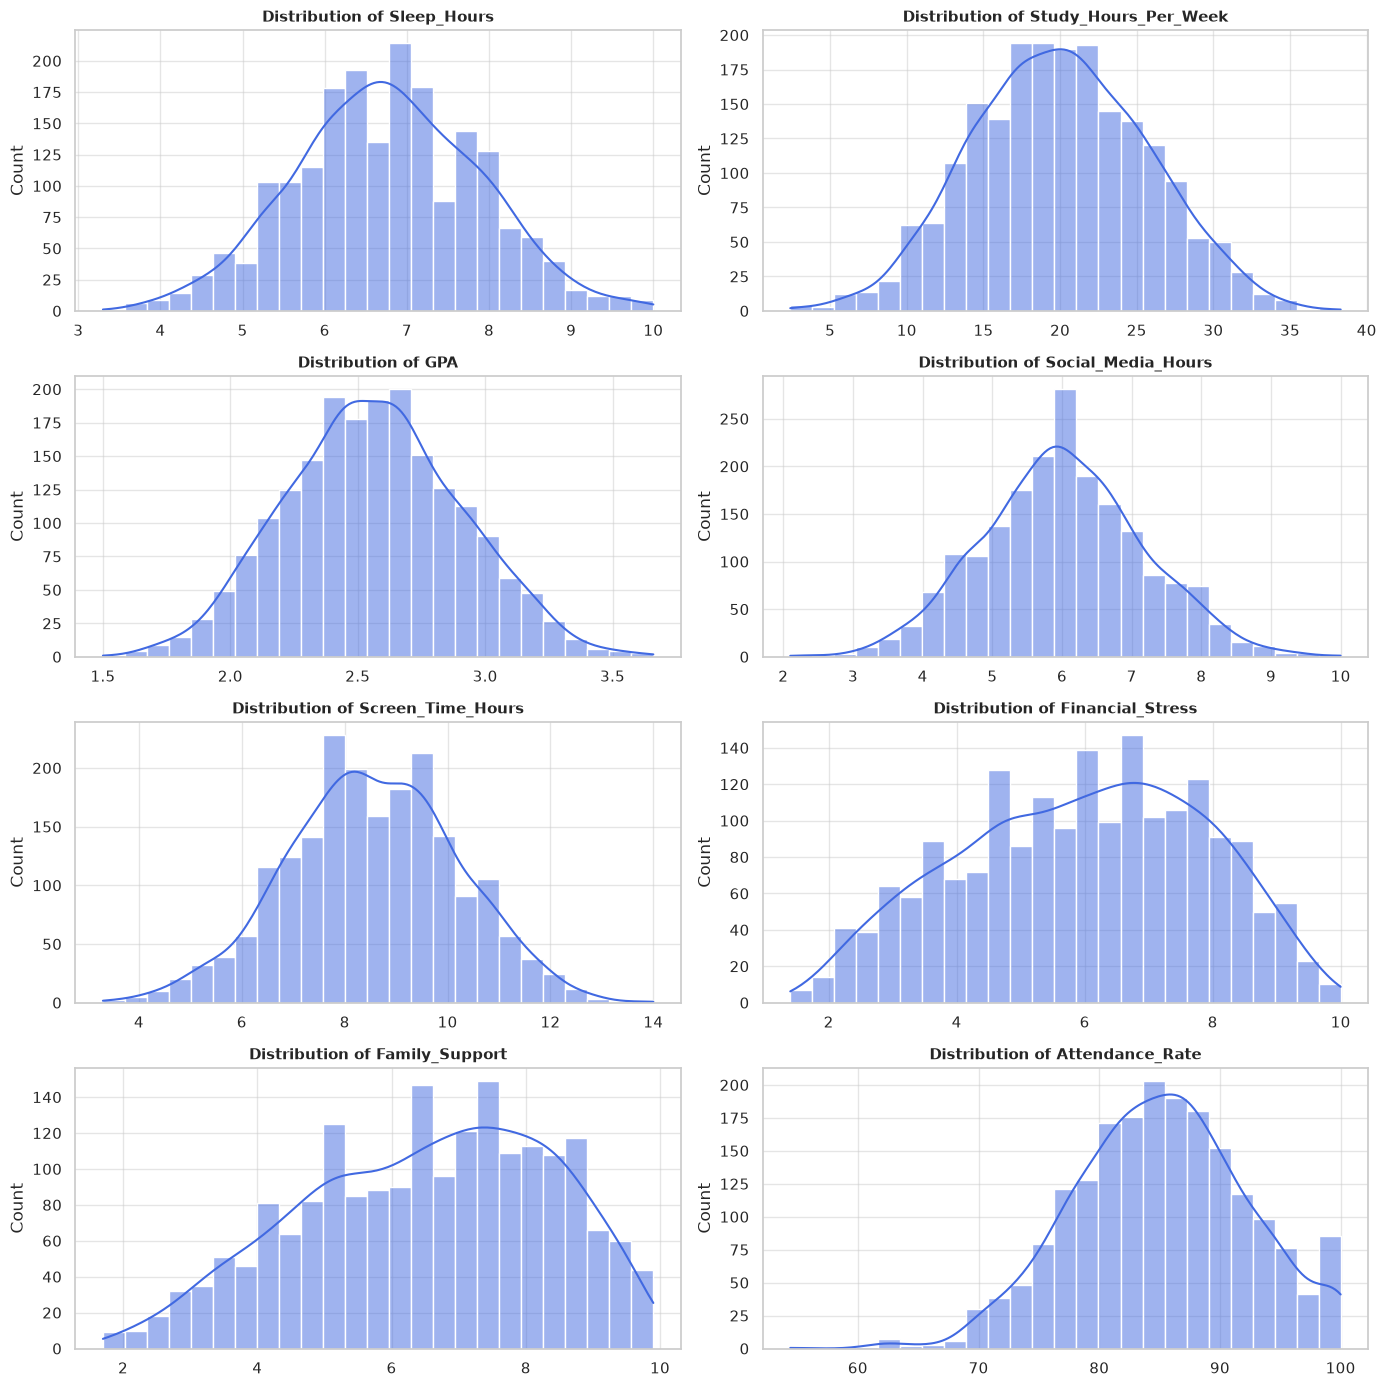

In [11]:
key_num_features = ['Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours',
                    'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 14))
axes = axes.flatten()

for i, col in enumerate(key_num_features):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='royalblue', bins=25)
    axes[i].set_title(f'Distribution of {col}', weight='bold', fontsize=11)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.savefig(figures_dir / "numerical_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

### 7. Categorical Features Analysis
Let's inspect the categories and frequencies for non-numeric columns.

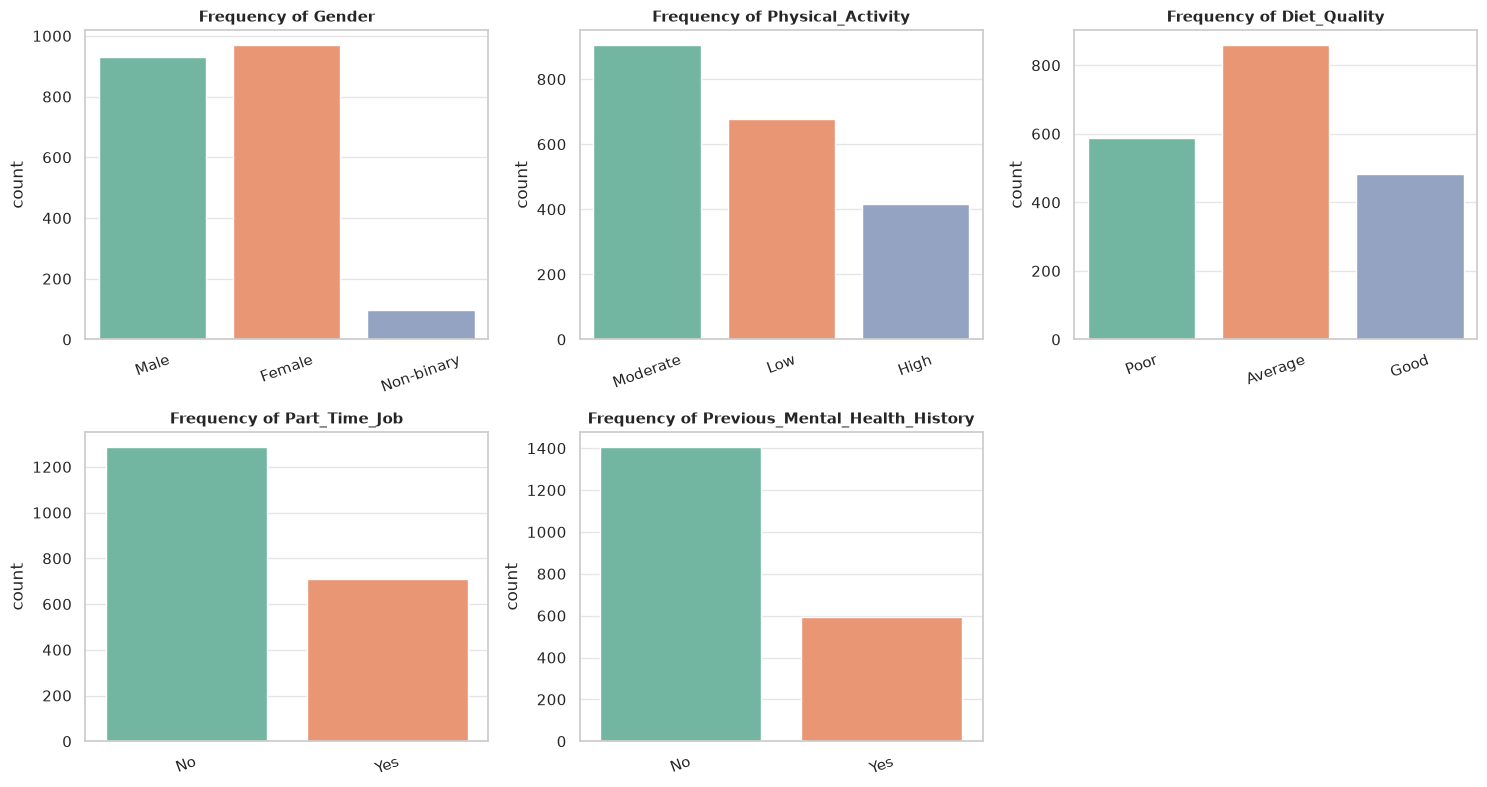

In [12]:
cat_cols = ['Gender', 'Physical_Activity', 'Diet_Quality', 'Part_Time_Job', 'Previous_Mental_Health_History']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i], hue=col, palette='Set2', legend=False)
    axes[i].set_title(f'Frequency of {col}', weight='bold', fontsize=11)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=20)

# Hide the 6th unused subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.savefig(figures_dir / "categorical_distributions.png", dpi=300, bbox_inches='tight')
plt.show()


### 8. Bivariate Analysis: What Factors Relate to Risk Level?
Now let's examine the relationships between our features and the `Mental_Health_Risk` target. This builds domain intuition and validates whether the data makes sense.

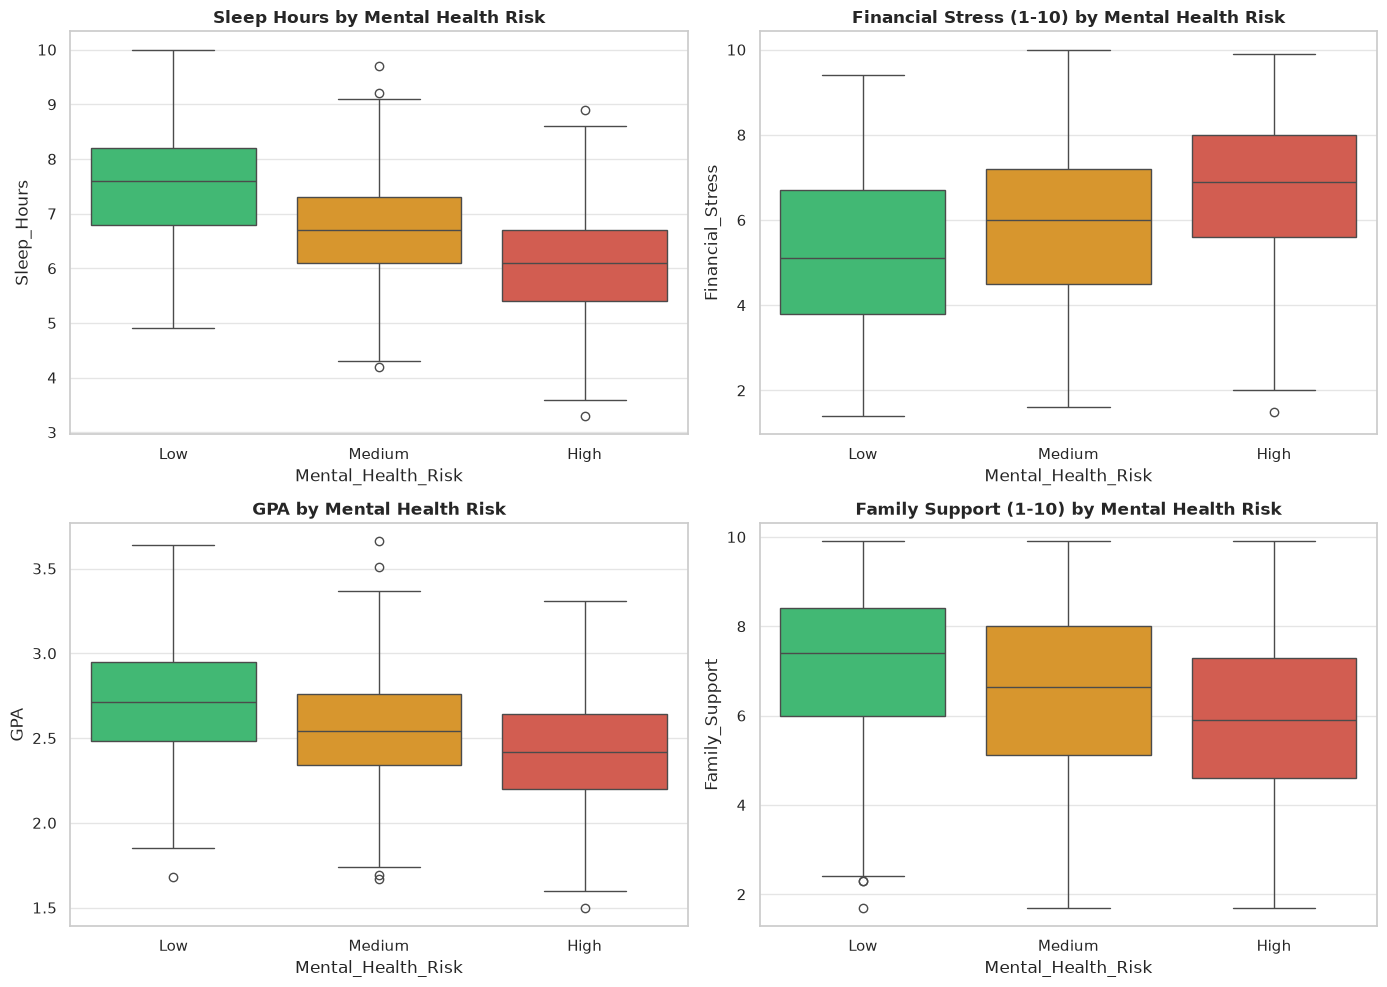

In [13]:
# Numerical vs Target (Boxplots)
risk_order = ['Low', 'Medium', 'High']
palette = {'Low': '#2ecc71', 'Medium': '#f39c12', 'High': '#e74c3c'}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Sleep Hours vs Risk
sns.boxplot(data=df, x='Mental_Health_Risk', y='Sleep_Hours', order=risk_order, hue='Mental_Health_Risk', palette=palette, legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Sleep Hours by Mental Health Risk', weight='bold')

# 2. Financial Stress vs Risk
sns.boxplot(data=df, x='Mental_Health_Risk', y='Financial_Stress', order=risk_order, hue='Mental_Health_Risk', palette=palette, legend=False, ax=axes[0, 1])
axes[0, 1].set_title('Financial Stress (1-10) by Mental Health Risk', weight='bold')

# 3. GPA vs Risk
sns.boxplot(data=df, x='Mental_Health_Risk', y='GPA', order=risk_order, hue='Mental_Health_Risk', palette=palette, legend=False, ax=axes[1, 0])
axes[1, 0].set_title('GPA by Mental Health Risk', weight='bold')

# 4. Family Support vs Risk
sns.boxplot(data=df, x='Mental_Health_Risk', y='Family_Support', order=risk_order, hue='Mental_Health_Risk', palette=palette, legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Family Support (1-10) by Mental Health Risk', weight='bold')

plt.tight_layout()
plt.savefig(figures_dir / "risk_vs_key_numerical.png", dpi=300, bbox_inches='tight')
plt.show()


Let's also look at how behavioral and categorical features break down across risk tiers.

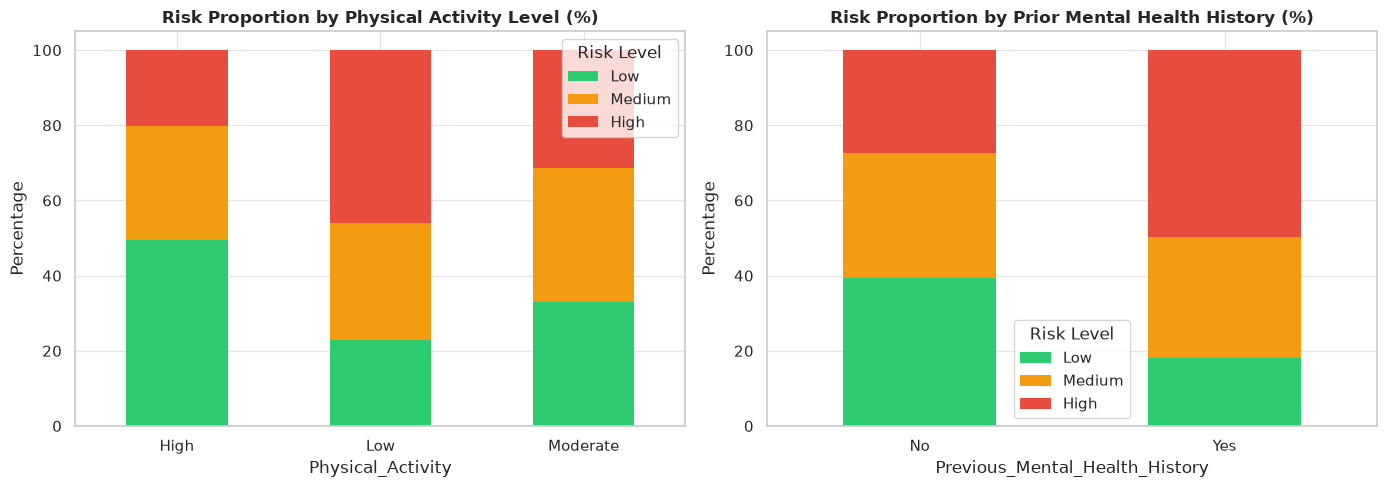

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Physical Activity vs Risk
activity_cross = pd.crosstab(df['Physical_Activity'], df['Mental_Health_Risk'], normalize='index')[risk_order] * 100
activity_cross.plot(kind='bar', stacked=True, color=['#2ecc71', '#f39c12', '#e74c3c'], ax=axes[0], edgecolor='none')
axes[0].set_title('Risk Proportion by Physical Activity Level (%)', weight='bold')
axes[0].set_ylabel('Percentage')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Risk Level')

# Previous Mental Health History vs Risk
history_cross = pd.crosstab(df['Previous_Mental_Health_History'], df['Mental_Health_Risk'], normalize='index')[risk_order] * 100
history_cross.plot(kind='bar', stacked=True, color=['#2ecc71', '#f39c12', '#e74c3c'], ax=axes[1], edgecolor='none')
axes[1].set_title('Risk Proportion by Prior Mental Health History (%)', weight='bold')
axes[1].set_ylabel('Percentage')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Risk Level')

plt.tight_layout()
plt.savefig(figures_dir / "risk_vs_categorical.png", dpi=300, bbox_inches='tight')
plt.show()

### 9. Correlation Analysis
Let's inspect linear correlations between all numerical features. (We also map `Mental_Health_Risk` ordinally to numeric: Low=0, Medium=1, High=2 to check correlation with the target).

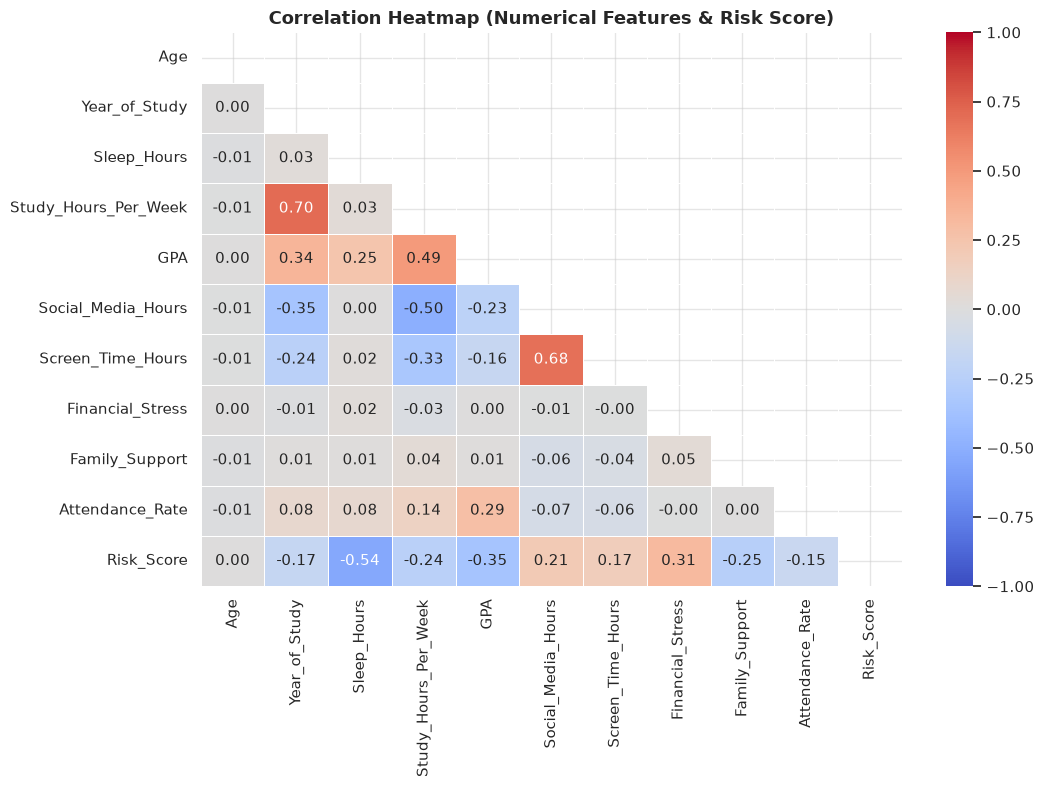

In [17]:
# Create temporary numeric target for correlation check
corr_df = df[num_cols].copy()
target_map = {'Low': 0, 'Medium': 1, 'High': 2}
corr_df['Risk_Score'] = df['Mental_Health_Risk'].map(target_map)

corr_matrix = corr_df.corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, mask=mask, linewidths=0.5)
plt.title('Correlation Heatmap (Numerical Features & Risk Score)', fontsize=13, weight='bold')
plt.tight_layout()
plt.savefig(figures_dir / "correlation_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

### 10. Summary of Findings & Action Plan for Preprocessing

#### Key Findings from EDA:
1. **Target**: `Mental_Health_Risk` is balanced (~33% per class). No class imbalance correction required.
2. **Identifier**: `Student_ID` is purely an ID and must be dropped.
3. **Missing Data**: 7 features have missing values (1.9%–4.5%).
   - Numerical (`Financial_Stress`, `Sleep_Hours`, `Social_Media_Hours`, `Family_Support`, `Attendance_Rate`, `GPA`): Impute using **Median**.
   - Categorical (`Diet_Quality`): Impute using **Mode** (most frequent).
4. **Strongest Predictors Observed**:
   - `Sleep_Hours` (Negative correlation: low sleep strongly associated with high risk).
   - `Financial_Stress` (Positive correlation: high stress strongly associated with high risk).
   - `Family_Support` & `Physical_Activity` (Protective factors: higher values associated with low risk).
   - `Previous_Mental_Health_History` (Students with prior history have a significantly higher rate of high risk).
5. **Categorical Encoding Strategy**:
   - Ordinal features: `Diet_Quality` (Poor < Average < Good), `Physical_Activity` (Low < Moderate < High) -> Ordinal encoding or One-Hot encoding.
   - Nominal/Binary features: `Gender`, `Part_Time_Job`, `Previous_Mental_Health_History` -> One-Hot encoding.
6. **Feature Scaling**: Numerical features have different scales (e.g. `GPA` 1.5–4.0 vs `Attendance_Rate` 30–100). Algorithms like Logistic Regression will require standard scaling.